In [1]:
import numpy as np
import sklearn.linear_model
import matplotlib.pyplot as plt

## Dataset

X: 
SHAPE = (1034, 1)
[[1.62110522]
 [1.76461064]
 [1.75572064]
 [1.66003453]
 [1.72650074]]

Y: 
SHAPE = (1034, 1)
[[54.87610387]
 [62.17308969]
 [55.15996198]
 [56.93205665]
 [46.37501175]]



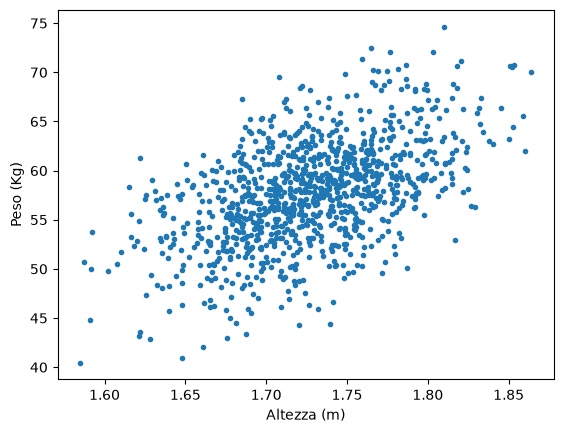

In [2]:
ds = np.genfromtxt('../datasets/ds_altezzapeso.csv', delimiter=';')
x = ds[:,:1]
y = ds[:,1:]

print(f"X: \nSHAPE = {x.shape}")
print(f"{x[0:5,:]}\n")
print(f"Y: \nSHAPE = {y.shape}")
print(f"{y[0:5,:]}\n")

plt.xlabel("Altezza (m)")
plt.ylabel("Peso (Kg)")
plt.plot(x,y,'.')
plt.show()

## Regressione Lineare

### Metodo 1: Regressore Lineare di Scikit-learn

Parametri:
57.403 -41.406

Regressore lineare:
y = 57.40x -41.41


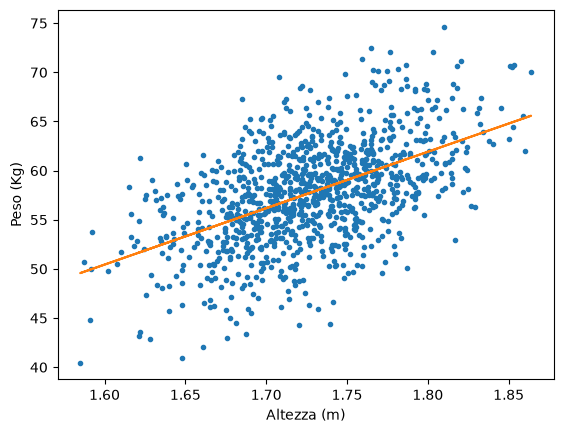

In [3]:
lin_reg = sklearn.linear_model.LinearRegression()
lin_reg.fit(x, y)

print("Parametri:")
print('%.3f' % (lin_reg.coef_[0][0]), '%.3f' % (lin_reg.intercept_[0]))
print()

print("Regressore lineare:")
print(f"y = {lin_reg.coef_[0][0]:.2f}x {lin_reg.intercept_[0]:+.2f}")
yt = lin_reg.coef_[0] * x + lin_reg.intercept_

plt.xlabel("Altezza (m)")
plt.ylabel("Peso (Kg)")
plt.plot(x,y,'.')
plt.plot(x,yt,'-')
plt.show()

### Metodo 2: Soluzione in forma chiusa


In [4]:
x1 = np.hstack([x, np.ones_like(x)]) # Portiamo in coordinate omogenee

w = np.linalg.pinv(x1.T@x1)@x1.T@y
w = w.T[0]

print("Parametri:")
print(w)
print()

print("Regressore lineare:")
print(f"y = {w[0]:.2f}x {w[1]:+.2f}")

Parametri:
[ 57.40254783 -41.40550287]

Regressore lineare:
y = 57.40x -41.41


### Metodo 3: - Risolvere il sistema lineare

In [5]:
ls = np.linalg.solve(x1.T@x1, x1.T@y)
ls = ls.T[0]
print("Parametri:")
print(ls)
print()

print("Regressore lineare:")
print(f"y = {ls[0]:.2f}x {ls[1]:+.2f}")

Parametri:
[ 57.40254783 -41.40550287]

Regressore lineare:
y = 57.40x -41.41


### Metodo 4: Regressione Polinomiale con grado 1


In [6]:
poly_reg = np.polyfit(x[:,0], y[:,0], deg=1)

print("Parametri:")
print(poly_reg)
print()

print("Regressore lineare:")
print(f"y = {poly_reg[0]:.2f}x {poly_reg[1]:+.2f}")

Parametri:
[ 57.40254783 -41.40550287]

Regressore lineare:
y = 57.40x -41.41
